California Housing Price Prediction and Model Deployment
Assignment.

 Objective
The objective of this assignemnt is to build an end-to-end machine learning workflow for predicting median house values using the California Housing dataset.

The project applies data preprocessing using ColumnTransformer, an 80/20 train-test split, K-Nearest Neighbours regression, five-fold cross-validation, and hyperparameter tuning using GridSearchCV.

The final model will be evaluated using the R² score and saved using joblib so that it can be reused for future predictions and deployment.

SETUP AND IMPORTS

In [19]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_california_housing

# Data preparation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning model
from sklearn.neighbors import KNeighborsRegressor

# Model evaluation
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Saving and loading the model
import joblib



LOAD THE CALIFORNIA HOUSING DATASET

In [20]:
# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Create the features dataset
X = housing.data.copy()

# Create the target variable
y = housing.target.copy()

# Combine the features and target for exploration
df = X.copy()
df["MedHouseVal"] = y

print("California Housing dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

California Housing dataset loaded successfully.
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Confirm the Feature Names

In [21]:
print("Feature names:")

for number, feature in enumerate(X.columns, start=1):
    print(f"{number}. {feature}")

Feature names:
1. MedInc
2. HouseAge
3. AveRooms
4. AveBedrms
5. Population
6. AveOccup
7. Latitude
8. Longitude


Confirm the Target Variable

In [22]:
print("Target variable:", housing.target_names)

Target variable: ['MedHouseVal']


The California Housing dataset was loaded using the fetch_california_housing() function from scikit-learn. The dataset contains 20,640 observations, eight numerical input features, and one target variable.

The input features were stored in X, while the target variable was stored in y. The target variable, MedHouseVal, represents the median house value in units of $100,000.

A Pandas DataFrame was created to make it easier to explore and analyse the dataset.

Explore the Dataset

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


The dataset information was checked to understand the number of observations, columns, and data types.

The California Housing dataset contains 20,640 observations and 9 columns, consisting of 8 input features and 1 target variable. All features are numerical.

Check for Missing Values

In [24]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


The dataset was checked for missing values before preprocessing. No missing values were found, meaning that no missing-value treatment was required.

Basic Statistics

In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Basic statistics were examined to understand the range, average, and spread of the different features.

The results show that the features have different numerical ranges. Therefore, feature scaling will be important for the K-Nearest Neighbours model because KNN uses distances between observations when making predictions.

View the Target Distribution

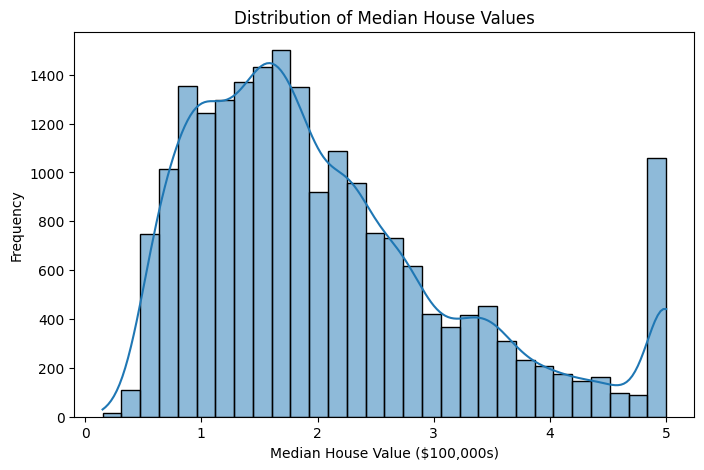

In [26]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["MedHouseVal"],
    bins=30,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000s)")
plt.ylabel("Frequency")
plt.show()

The histogram shows the distribution of median house values in the dataset. It helps us understand how housing values are spread before building the regression model.

Split the Data

Now divide the dataset into 80% training data and 20% testing data, as required by the assignment.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


The dataset was divided into training and testing sets using an 80/20 split. The training set contains 16,512 observations, while the test set contains 4,128 observations.

The training data will be used to train and tune the KNN regression model, while the test data will be used to evaluate the final model on unseen data.

Preprocessing Using ColumnTransformer

All eight features in the California Housing dataset are numerical, so we will apply StandardScaler to them.

In [28]:
# Select all numerical features
numerical_features = X.columns.tolist()

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features)
    ]
)

print("Preprocessor created successfully.")
print("Features to be scaled:")
print(numerical_features)

Preprocessor created successfully.
Features to be scaled:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


A ColumnTransformer was created to preprocess the input features. Since all eight features in the California Housing dataset are numerical, StandardScaler was applied to standardize them. Scaling is important for K-Nearest Neighbours because the model uses distances between data points when making predictions.

Create the KNN Pipeline

In [29]:
# Create the KNN regression pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsRegressor())
])

print("KNN pipeline created successfully.")

KNN pipeline created successfully.


A machine learning pipeline was created to combine preprocessing and the K-Nearest Neighbours regression model. The pipeline ensures that feature scaling is applied consistently before the model makes predictions.

Define the Hyperparameters

In [30]:
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

print("Hyperparameter grid:")
print(param_grid)

Hyperparameter grid:
{'knn__n_neighbors': [3, 5, 7, 9], 'knn__weights': ['uniform', 'distance'], 'knn__p': [1, 2]}


Configure GridSearchCV

In [31]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

print("GridSearchCV configured successfully.")

GridSearchCV configured successfully.


GridSearchCV was used to find the best combination of KNN hyperparameters. Sixteen parameter combinations were evaluated using 5-fold cross-validation. The R² score was used to compare the performance of the models.

Train and Tune the Model

In [32]:
# Train the model and perform hyperparameter tuning
grid_search.fit(X_train, y_train)

print("Training and hyperparameter tuning completed.")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Training and hyperparameter tuning completed.


GridSearchCV is testing:

16 parameter combinations
Using 5-fold cross-validation

So it performs 80 model fits.

Display the Best Parameters

In [33]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation R² Score:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'distance'}

Best Cross-Validation R² Score:
0.7313


GridSearchCV tested different combinations of the KNN hyperparameters using 5-fold cross-validation. The best combination was selected based on the highest R² score.

Evaluate the Final Model

In [34]:
best_model = grid_search.best_estimator_

# Make predictions
y_pred = best_model.predict(X_test)

# Calculate R²
test_r2 = r2_score(y_test, y_pred)

print("Test R² Score:", round(test_r2, 4))

Test R² Score: 0.7221


The final KNN model achieved an R² score of 0.7221 on the test dataset. This means that the model explains approximately 70% of the variation in median house values.

Save the Trained Pipeline

In [35]:
# Save the trained pipeline
joblib.dump(best_model, "california_housing_knn_model.pkl")

print("Model saved successfully.")

Model saved successfully.


Test the Saved Model

In [36]:
# Load the saved model
loaded_model = joblib.load(
    "california_housing_knn_model.pkl"
)

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Evaluate the loaded model
loaded_r2 = r2_score(
    y_test,
    loaded_predictions
)

print("Loaded Model R² Score:", round(loaded_r2, 4))

Loaded Model R² Score: 0.7221


The final trained pipeline was saved using Joblib. The saved model was loaded again and tested successfully, showing that it can be reused for predictions without retraining.

In [37]:
%%writefile requirements.txt
streamlit
pandas
scikit-learn
joblib

Overwriting requirements.txt


In [38]:
!cat requirements.txt

streamlit
pandas
scikit-learn
joblib


In [39]:
!pip install streamlit -q

In [ ]:
!streamlit run app.py



2026-11-08 16:43:57.576 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.236.223.183:8501

